# Notebook 11 - EDA Visualization
Sprint 4 - EDA

In this notebook I create the mandatory visualizations: histogram, box plot, bar chart, count plot, scatter plot, line plot, violin plot, distribution plot, pair plot and heatmap. The earlier notebooks already used some of these plots to check basic things, so here I use each plot to answer a new question about churn, and I do not repeat a chart without a reason. For every visualization I write why I selected it, I generate it, I interpret it and I state the insight.

**Dataset:** Telco Customer Churn (Kaggle, 7043 rows and 21 columns)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

# working copy for visualization only
df_viz = df.copy()
df_viz["TotalCharges"] = pd.to_numeric(df_viz["TotalCharges"], errors="coerce")
df_viz["Churn_num"] = (df_viz["Churn"] == "Yes").astype(int)

contract_order = ["Month-to-month", "One year", "Two year"]
overall_rate = df_viz["Churn_num"].mean() * 100

print("Overall churn rate:", round(overall_rate, 1), "%")

Overall churn rate: 26.5 %


## 1. Histogram

**Why this plot was selected:** A histogram shows how many customers fall in each range of a numerical variable. The univariate notebook already showed the tenure histogram for all customers. Here I split the bars by Churn, so the plot answers a different question: at which tenure do the churned customers appear? A stacked histogram is a good choice because the bar height still shows the total customers and the color shows the churn part.

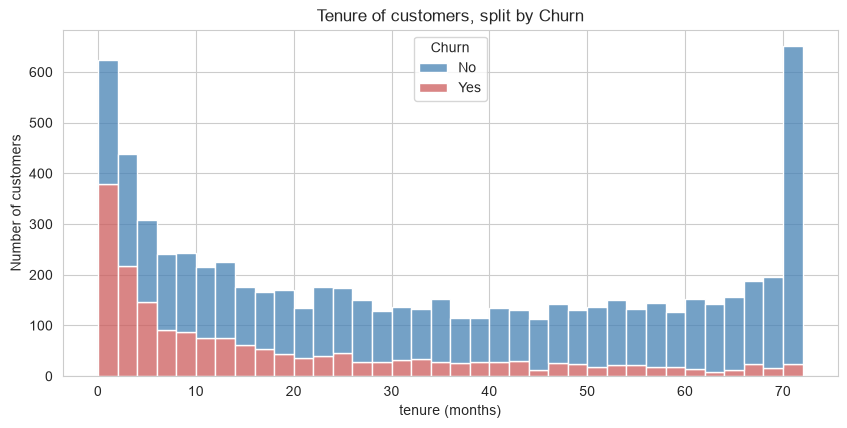

In [2]:
plt.figure(figsize=(10, 4.5))
sns.histplot(data=df_viz, x="tenure", hue="Churn", bins=36, multiple="stack",
             palette={"No": "steelblue", "Yes": "indianred"})
plt.title("Tenure of customers, split by Churn")
plt.xlabel("tenure (months)")
plt.ylabel("Number of customers")
plt.show()

**What the code does:** It draws a stacked histogram of tenure with 36 bins, where each bar is split into the churned (red) and not churned (blue) customers.

**Why this method was used:** Stacking shows both the size of each tenure range and the share of churners inside it. A plain histogram would hide the target.

**What the output means (interpretation):** The first bars (the first months) are tall and a large part of each is red. As tenure increases the red part becomes small, and the tall bar at the end (about 72 months) is almost completely blue.

**Insight obtained:** Churn is concentrated in the first months, and the customers who reach the end of the range hardly ever churn. The business problem is therefore to keep new customers through the first year.

**Effect on the ML pipeline:** Tenure is a strong feature, and its relationship with the target is not linear, because the churn share falls quickly at first and then slowly. A tree based model or tenure groups can capture this better than a straight line.

## 2. Box Plot

**Why this plot was selected:** A box plot compares the median and the spread of a numerical variable across categories. I want to know how the contract type relates to tenure, and whether churned customers within the same contract type stayed for a shorter time. Adding Churn as a second grouping answers both in one plot, which two separate plots could not do as clearly.

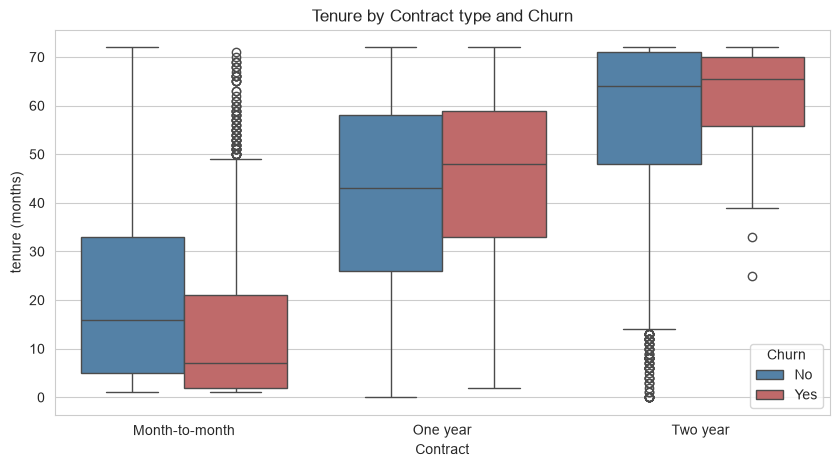

Churn             No   Yes
Contract                  
Month-to-month  16.0   7.0
One year        43.0  48.0
Two year        64.0  65.5


In [3]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df_viz, x="Contract", y="tenure", hue="Churn", order=contract_order,
            palette={"No": "steelblue", "Yes": "indianred"})
plt.title("Tenure by Contract type and Churn")
plt.ylabel("tenure (months)")
plt.show()

print(df_viz.groupby(["Contract", "Churn"])["tenure"].median().unstack())

**What the code does:** It draws box plots of tenure for each contract type, with one box for churned and one for not churned customers, and prints the median tenure of each of the six groups.

**Why this method was used:** The box plot gives the median, the quartiles and the spread of each group, so a group comparison does not depend on the mean, and the printed medians give the exact numbers.

**What the output means (interpretation):** The median tenure rises from month-to-month to one year to two year contracts. Inside each contract type, the churned customers have a lower median tenure than the customers who stayed.

**Insight obtained:** Contract type and tenure are strongly linked, because long contracts are held by long term customers. The month-to-month group has a low tenure whether or not customers churn, so it is the group with the least loyalty history. Within every contract type, churned customers left earlier than the others stayed.

**Effect on the ML pipeline:** Contract and tenure carry overlapping information, which is something to keep in mind for multicollinearity and for the interpretation of feature importance.

## 3. Bar Chart

**Why this plot was selected:** A bar chart compares one value across a few categories, and it is the right choice to compare churn rates between groups. The earlier notebooks compared churn rates for the original features. Here I create a new feature, the number of protective services a customer has (online security, online backup, device protection and tech support), and ask whether customers with more services churn less. I only use customers with internet service, because customers without internet cannot have these services, and they have a very low churn rate that would distort the result.

           customers  churn_rate_%
n_protect                         
0               1267          56.7
1               1467          38.9
2               1372          23.8
3                941          12.4
4                470           5.3


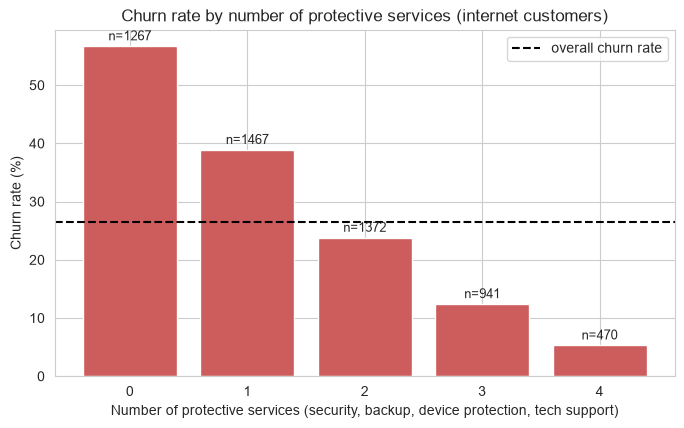

In [4]:
protect = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport"]
internet_customers = df_viz[df_viz["InternetService"] != "No"].copy()
internet_customers["n_protect"] = (internet_customers[protect] == "Yes").sum(axis=1)

summary = internet_customers.groupby("n_protect")["Churn_num"].agg(["count", "mean"])
summary["mean"] = (summary["mean"] * 100).round(1)
print(summary.rename(columns={"count": "customers", "mean": "churn_rate_%"}))

plt.figure(figsize=(8, 4.5))
plt.bar(summary.index.astype(str), summary["mean"], color="indianred")
for i, (rate, n) in enumerate(zip(summary["mean"], summary["count"])):
    plt.text(i, rate + 1, "n=" + str(n), ha="center", fontsize=9)
plt.axhline(overall_rate, color="black", linestyle="--", label="overall churn rate")
plt.xlabel("Number of protective services (security, backup, device protection, tech support)")
plt.ylabel("Churn rate (%)")
plt.title("Churn rate by number of protective services (internet customers)")
plt.legend()
plt.show()

**What the code does:** It counts how many of the four protective services each internet customer has, calculates the churn rate and number of customers for each count, and draws a bar chart with the customer numbers written on the bars and a line at the overall churn rate.

**Why this method was used:** A bar chart is the clearest way to compare a rate across a small number of ordered groups, and the number of customers on each bar shows whether the rate is reliable.

**What the output means (interpretation):** The churn rate is highest for customers with no protective service and decreases as the number of services increases, and it is far below the overall rate for customers with three or four services.

**Insight obtained:** Customers who use more protective services are much more loyal. This could be because the services make leaving harder, or because engaged customers choose more services, so it does not prove a cause. As a business action, offering a protective bundle to customers with none is a possible retention idea that can be tested.

**Effect on the ML pipeline:** The count of protective services is a useful engineered feature that sums several overlapping columns into one. It could replace the four separate columns, and this would reduce the multicollinearity found among them.

## 4. Count Plot

**Why this plot was selected:** A count plot shows how many customers are in each category, and with a second variable as color it shows the customer mix. I use it to see how the three contract types are divided among the three internet service types. This tells me which customer segments are big, and so which segments matter most for the business.

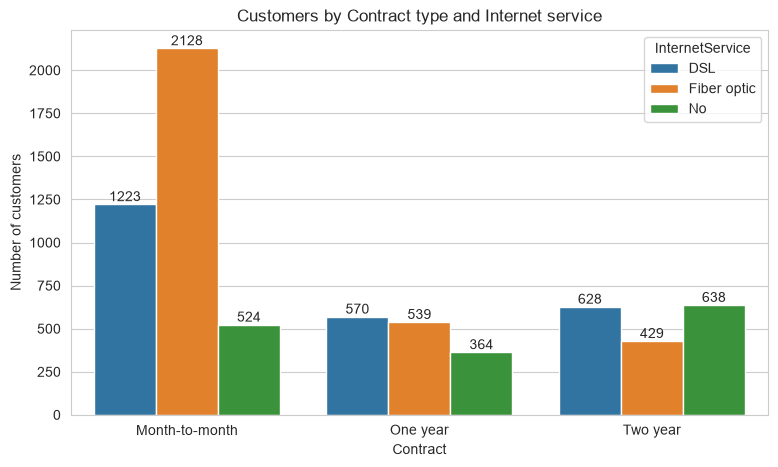

In [5]:
plt.figure(figsize=(9, 5))
ax = sns.countplot(data=df_viz, x="Contract", hue="InternetService", order=contract_order,
                   hue_order=["DSL", "Fiber optic", "No"])
for container in ax.containers:
    ax.bar_label(container)
plt.title("Customers by Contract type and Internet service")
plt.ylabel("Number of customers")
plt.show()

**What the code does:** It draws a count plot of the Contract types with one bar for each internet service type, and writes the customer numbers on the bars.

**Why this method was used:** A count plot shows the size of each segment directly, and the numbers on the bars make the comparison exact.

**What the output means (interpretation):** The month-to-month contract has the most customers, and within it the fiber optic bar is the largest. In one year and two year contracts the bars are lower, and the no internet service group is more frequent among the long contracts than among month-to-month customers.

**Insight obtained:** The month-to-month fiber optic customers are the biggest single segment of the business, and they are also the segment with the highest churn rate found earlier. This is where retention work has the biggest effect on revenue.

**Effect on the ML pipeline:** Segment sizes tell me where the model will see most examples. The combination of contract and internet service is a strong interaction, and a model should be able to learn it, either with a tree based method or with an interaction feature.

## 5. Scatter Plot

**Why this plot was selected:** A scatter plot shows the relationship between two numerical variables. Earlier I looked at tenure against MonthlyCharges and found almost no correlation. Here I color the points by internet service type, to test whether the price level is explained by the type of service and not by how long the customer has stayed.

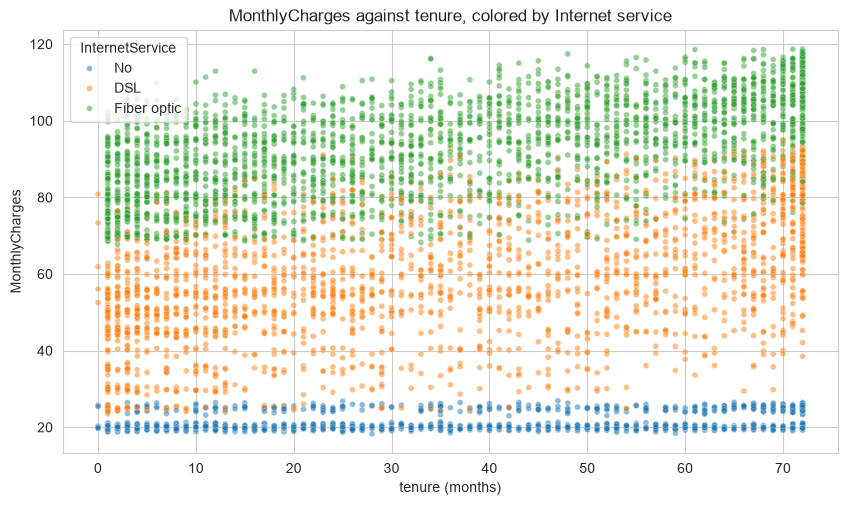

                  min  median    max
InternetService                     
DSL              23.4    56.2   94.8
Fiber optic      67.8    91.7  118.8
No               18.2    20.2   26.9


In [6]:
plt.figure(figsize=(10, 5.5))
sns.scatterplot(data=df_viz, x="tenure", y="MonthlyCharges", hue="InternetService",
                hue_order=["No", "DSL", "Fiber optic"], alpha=0.5, s=18)
plt.title("MonthlyCharges against tenure, colored by Internet service")
plt.xlabel("tenure (months)")
plt.show()

print(df_viz.groupby("InternetService")["MonthlyCharges"].agg(["min", "median", "max"]).round(1))

**What the code does:** It draws a scatter plot of tenure against MonthlyCharges with the points colored by internet service type, and prints the minimum, median and maximum monthly charges of each type.

**Why this method was used:** A color for a third variable adds the explanation to the scatter plot, and the table gives the exact ranges behind the colors.

**What the output means (interpretation):** The points form horizontal layers and not an upward or downward trend. The no internet customers are in a low layer at the bottom, the DSL customers are in the middle with a wide range, and the fiber optic customers are in the top layer. The layers do not change with tenure.

**Insight obtained:** The monthly price is decided mainly by the service type (and the add-ons taken), and not by how long the customer has stayed, which explains the weak correlation between tenure and MonthlyCharges. Long term customers do not pay more or less per month than new ones in the same service type.

**Effect on the ML pipeline:** InternetService should be kept as a feature together with MonthlyCharges, because MonthlyCharges alone mixes three different groups. A model can use the combination to separate expensive fiber customers from cheap basic customers.

## 6. Line Plot

**Why this plot was selected:** A line plot shows how a value changes along an ordered variable. Notebook 10 showed the churn rate by tenure for all customers in one line. Here I draw one line for each contract type, to test whether the early churn pattern is the same for every contract, or whether contract type changes the shape of the curve.

Number of customers in each group:
Contract     Month-to-month  One year  Two year
tenure_band                                    
0-12                   1994       124        68
13-24                   737       197        90
25-48                   802       518       274
49-72                   342       634      1263


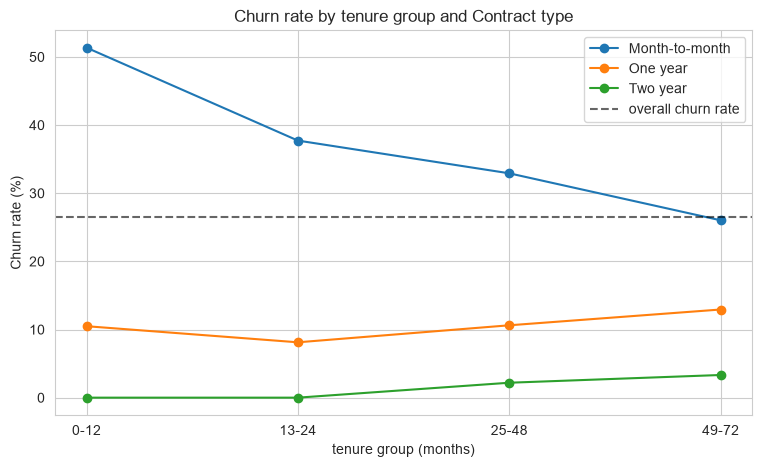

In [7]:
bands = pd.cut(df_viz["tenure"], bins=[-1, 12, 24, 48, 72], labels=["0-12", "13-24", "25-48", "49-72"])
df_viz["tenure_band"] = bands

rate = df_viz.pivot_table(index="tenure_band", columns="Contract", values="Churn_num", aggfunc="mean", observed=True) * 100
size = df_viz.pivot_table(index="tenure_band", columns="Contract", values="Churn_num", aggfunc="count", observed=True)

print("Number of customers in each group:")
print(size)

plt.figure(figsize=(9, 5))
for contract in contract_order:
    plt.plot(rate.index.astype(str), rate[contract], marker="o", label=contract)
plt.axhline(overall_rate, color="black", linestyle="--", alpha=0.6, label="overall churn rate")
plt.xlabel("tenure group (months)")
plt.ylabel("Churn rate (%)")
plt.title("Churn rate by tenure group and Contract type")
plt.legend()
plt.show()

**What the code does:** It groups tenure into four bands, calculates the churn rate for each band and contract type, prints the number of customers in each group, and draws one line per contract type.

**Why this method was used:** Lines show the trend along tenure, and several lines in one plot allow a direct comparison of contract types. I printed the group sizes because some groups, such as two year contracts in the first months, are very small.

**What the output means (interpretation):** All three lines fall as tenure increases. The month-to-month line is above the other two in every tenure group, the one year line is in the middle and the two year line is the lowest. Two year contracts in the first band have very few customers, so that point is not reliable.

**Insight obtained:** Contract type lowers the churn rate at every stage of the customer life, and tenure lowers it inside every contract type. The two effects add up, so the highest risk group is the new month-to-month customer, and the lowest risk group is the long term customer with a long contract.

**Effect on the ML pipeline:** Both features are useful, and each one remains informative when the other is known, so the model should keep both. The small groups warn me to be careful with conclusions drawn from them.

## 7. Violin Plot

**Why this plot was selected:** A violin plot shows the whole distribution of a numerical variable for each group, and with the split option two groups can be compared side by side in one shape. I want to check if churned and not churned customers pay different monthly amounts inside the same internet service type. If they do not, the higher average bill of churned customers seen earlier would come only from the mix of services.

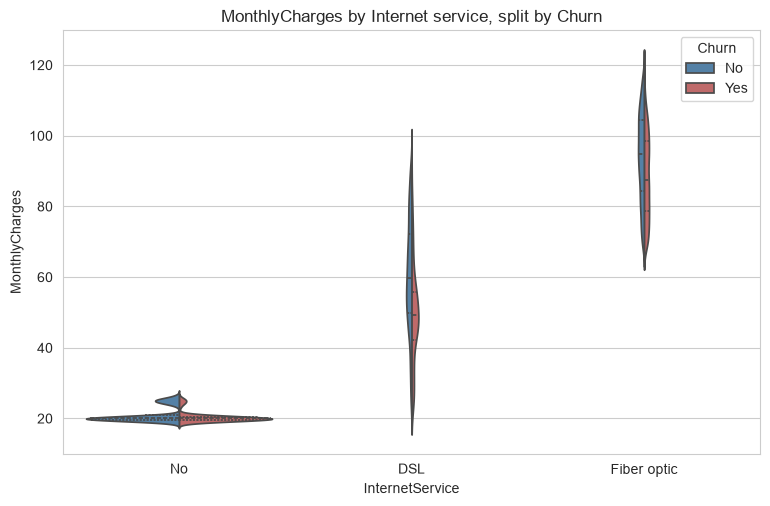

Churn              No   Yes
InternetService            
DSL              60.2  49.1
Fiber optic      93.9  88.1
No               21.1  20.4


In [8]:
plt.figure(figsize=(9, 5.5))
sns.violinplot(data=df_viz, x="InternetService", y="MonthlyCharges", hue="Churn", split=True,
               order=["No", "DSL", "Fiber optic"], inner="quart",
               palette={"No": "steelblue", "Yes": "indianred"})
plt.title("MonthlyCharges by Internet service, split by Churn")
plt.show()

print(df_viz.groupby(["InternetService", "Churn"])["MonthlyCharges"].mean().unstack().round(1))

**What the code does:** It draws a violin plot of MonthlyCharges for each internet service type, with the left half for not churned and the right half for churned customers, and prints the mean monthly charge of the six groups.

**Why this method was used:** The split violin shows the full shape of both groups in the same place, so I can compare the shape, the center and the spread, and the table adds the exact means.

**What the output means (interpretation):** The shapes of the two halves are similar inside each service type, and the means in the table are close to each other for the same service type, while the differences between service types are large.

**Insight obtained:** Inside a service type, churned and not churned customers pay nearly the same monthly amount. The higher average bill of churned customers overall is mainly due to the fact that more of them have fiber optic, which is the most expensive service, and not to a price difference within a service. So the price level alone is not the cause, and the service type matters more.

**Effect on the ML pipeline:** MonthlyCharges is a weaker feature than it looked in the overall comparison, once InternetService is known. This is a warning against reading the feature importance of MonthlyCharges as a pricing effect.

## 8. Distribution Plot (ECDF)

**Why this plot was selected:** A distribution plot shows how the values of a variable are spread. Histograms and KDE curves were used in the earlier notebooks. An empirical cumulative distribution plot (ECDF) is a different view: for any tenure on the x axis, it shows the share of customers who have a tenure up to that value. It does not depend on bin width, so it is a clean way to compare the tenure of the three contract groups, and to read percentages directly.

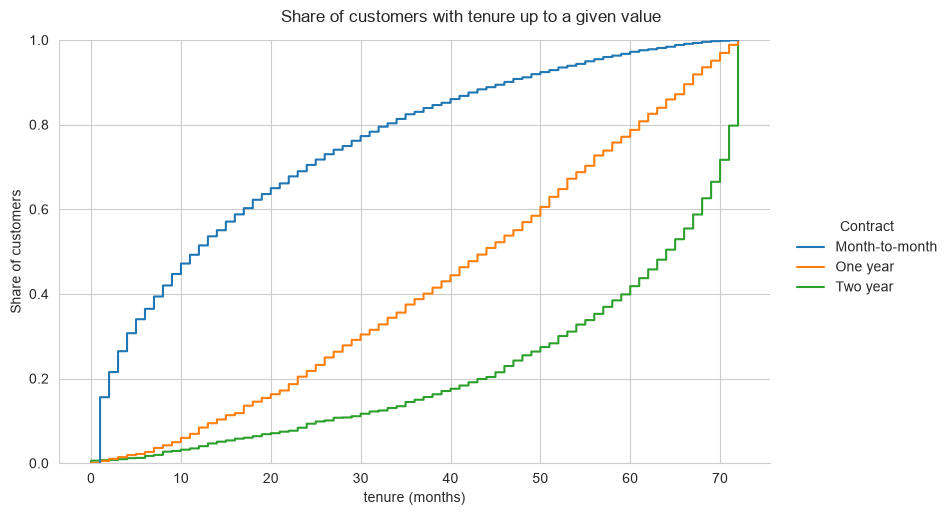

                0.25  0.50  0.75
Contract                        
Month-to-month   3.0  12.0  29.0
One year        27.0  44.0  58.0
Two year        48.0  64.0  71.0


In [9]:
g = sns.displot(data=df_viz, x="tenure", hue="Contract", hue_order=contract_order, kind="ecdf",
                height=5, aspect=1.6)
g.fig.suptitle("Share of customers with tenure up to a given value", y=1.02)
g.set_axis_labels("tenure (months)", "Share of customers")
plt.show()

print(df_viz.groupby("Contract")["tenure"].quantile([0.25, 0.5, 0.75]).unstack().loc[contract_order])

**What the code does:** It draws an ECDF of tenure for each contract type, so that each curve shows the share of customers whose tenure is less than or equal to each value, and prints the 25th, 50th and 75th percentiles of tenure for each contract.

**Why this method was used:** The ECDF avoids the choice of bins, lets me read the percentages from the y axis, and makes three groups easy to compare because the curves can be placed in the same plot.

**What the output means (interpretation):** The month-to-month curve rises fastest at the start and is the farthest to the left, which means most of its customers have a short tenure. The two year curve rises slowly and stays low for a long time, which means most of its customers have a long tenure. The one year curve is in between. The table gives the exact percentiles.

**Insight obtained:** Half of the month-to-month customers have a tenure of well under a year, while half of the two year customers have stayed for more than five years. This again shows that customers with flexible contracts are the most recent and the least settled.

**Effect on the ML pipeline:** The three contract groups differ strongly in their tenure distribution, so a model has to be evaluated on all of them, and the training data should contain enough examples from each group.

## 9. Pair Plot

**Why this plot was selected:** A pair plot shows all the pairs of numerical features and their distributions in one figure. In Notebook 6 I colored it by Churn and found that the classes overlap. Here I color it by Contract, to see if the contract groups are separated in the numerical space, which would show how much information the numerical features carry about the contract type, and if they form natural customer segments.

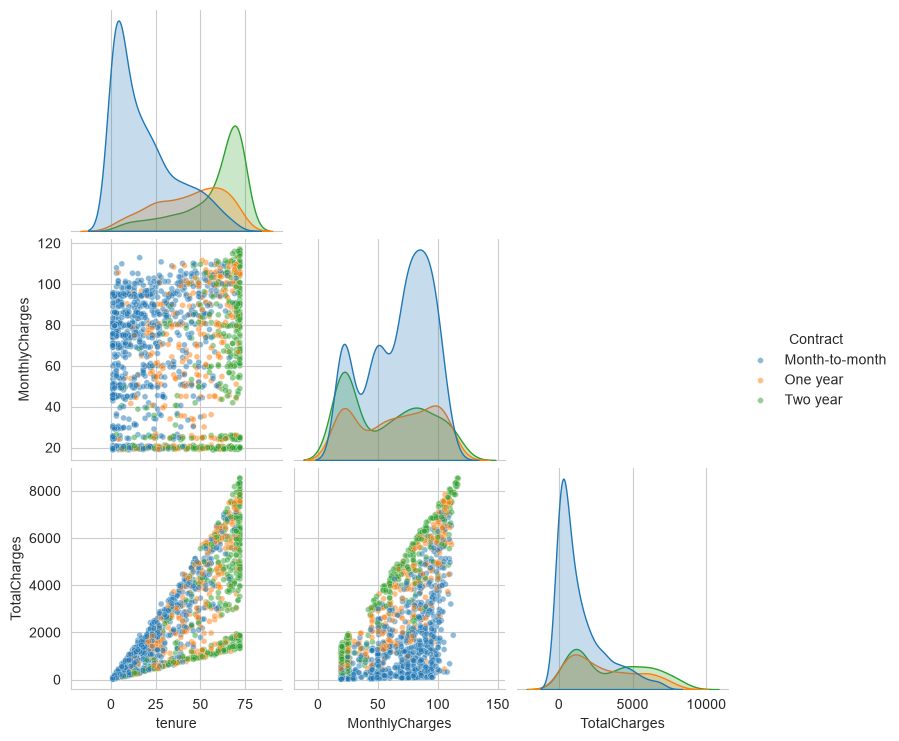

In [10]:
sample = df_viz[["tenure", "MonthlyCharges", "TotalCharges", "Contract"]].dropna().sample(1500, random_state=1)

sns.pairplot(sample, hue="Contract", hue_order=contract_order, corner=True,
             plot_kws={"alpha": 0.5, "s": 18})
plt.show()

**What the code does:** It takes a random sample of 1500 customers and draws a pair plot of the three numerical features, colored by Contract, with distributions on the diagonal.

**Why this method was used:** A pair plot gives all the numerical views at once, and the sample keeps the plot fast and readable without changing the picture.

**What the output means (interpretation):** On the diagonal for tenure the three contract types have clearly different distributions: month-to-month is concentrated at low values, two year at high values. In the plots that include TotalCharges the two year customers are on the upper part of the fan. For MonthlyCharges the three contract types overlap much more.

**Insight obtained:** Tenure separates the contract groups, and MonthlyCharges does not. TotalCharges separates them mostly because it grows with tenure. This confirms that the contract groups are mainly groups of loyalty and not of price.

**Effect on the ML pipeline:** Because tenure and contract overlap, linear models should be checked for multicollinearity, and the choice of encoding for Contract (ordinal or one-hot) can be tested against tenure based features.

## 10. Heatmap

**Why this plot was selected:** A heatmap shows a value for every combination of two categorical variables as colors, so the high risk and low risk combinations can be found quickly. The earlier heatmaps showed correlations and the combination of contract with internet service. Here I use PaymentMethod and Contract, to see if the high churn of electronic check users exists only because they are mostly on month-to-month contracts, or if it also appears inside each contract type. I hide the cells with fewer than 50 customers, because their rates are not reliable.

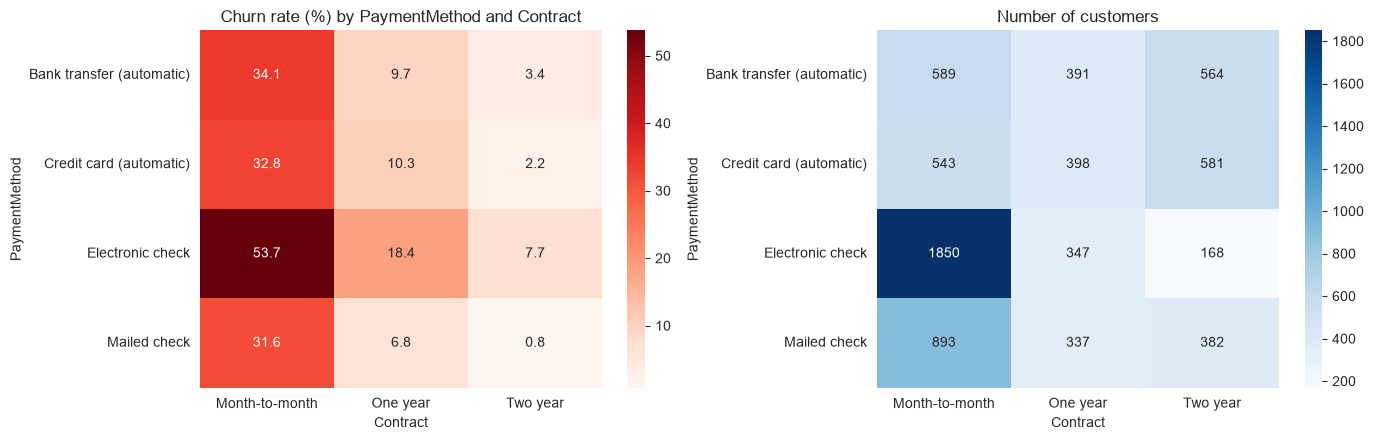

In [11]:
rate_pm = df_viz.pivot_table(index="PaymentMethod", columns="Contract", values="Churn_num", aggfunc="mean")[contract_order] * 100
size_pm = df_viz.pivot_table(index="PaymentMethod", columns="Contract", values="Churn_num", aggfunc="count")[contract_order]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.heatmap(rate_pm, annot=True, fmt=".1f", cmap="Reds", mask=(size_pm < 50), ax=axes[0])
axes[0].set_title("Churn rate (%) by PaymentMethod and Contract")
sns.heatmap(size_pm, annot=True, fmt=".0f", cmap="Blues", ax=axes[1])
axes[1].set_title("Number of customers")
plt.tight_layout()
plt.show()

**What the code does:** It calculates the churn rate and the number of customers for every combination of payment method and contract type, and draws two heatmaps side by side. The cells with fewer than 50 customers are hidden in the churn rate heatmap.

**Why this method was used:** A heatmap with a color scale lets me compare twelve cells at once, and the count heatmap shows how many customers each cell is based on.

**What the output means (interpretation):** The darkest cells are in the month-to-month column. Within the month-to-month column, electronic check has the highest churn rate. In the one year and two year columns all payment methods have low rates, and the differences between payment methods are much smaller.

**Insight obtained:** Electronic check users churn more even when they are compared with other customers on the same month-to-month contract, so the payment method has some effect of its own, although the contract effect is much larger. The difference shrinks for long contracts, so the effect of payment method depends on the contract type.

**Effect on the ML pipeline:** Payment method is a useful second feature after contract, and the interaction between them is a pattern that a tree based model can learn. It also suggests a business check, for example why electronic check customers are at higher risk.

# Summary of Visualizations

| Plot | Question it answered | Insight |
|---|---|---|
| Stacked histogram | At which tenure do churners appear? | Mostly in the first months, and almost never among the longest customers |
| Box plot | How do contract type and tenure relate? | Longer contracts mean longer tenure, and churners leave earlier inside every contract type |
| Bar chart | Do more protective services mean less churn? | Churn falls as the number of protective services rises |
| Count plot | How big are the contract and internet segments? | Month-to-month fiber optic is the biggest segment and the riskiest one |
| Scatter plot | Does the price depend on tenure? | No, it depends mainly on the service type |
| Line plot | Is the tenure effect the same for each contract? | Churn falls with tenure in all contracts, and month-to-month is always highest |
| Violin plot | Do churners pay more inside the same service? | The distributions are similar, so the service type explains most of the price gap |
| ECDF | How different is tenure across contracts? | Month-to-month customers are far more recent |
| Pair plot | Do numerical features separate the contracts? | Tenure does, MonthlyCharges hardly does |
| Heatmap | Does payment method matter inside a contract? | Electronic check is riskier in month-to-month contracts, and the gap shrinks in long contracts |

# Overall Visual Findings

- Churn is an early life problem, concentrated in the first year of the customer life.
- Contract type is the strongest single separator, and tenure and contract overlap.
- The biggest and riskiest segment is the month-to-month fiber optic customer.
- Price level is explained mostly by the service type, so MonthlyCharges must be read together with InternetService.
- Protective services and automatic payments go with lower churn, but these are associations and not proven causes.


**What I learned:** A chart should be chosen to answer a specific question, and adding a second variable (color, split or a second line) often turns a simple chart into an explanation. I also learned to print the group sizes next to every rate, because a rate from a few customers can be misleading.
